# EA2 · Modelos de predicción y clasificación

**Dataset:** [`jdavit/colombian-conflict-SQA`](https://huggingface.co/datasets/jdavit/colombian-conflict-SQA), unas 2.900 preguntas y respuestas en español sobre informes del conflicto armado colombiano.

| Etapa | Qué se hace |
|---|---|
| 1 · Extracción | `HFDatasetLoader` descarga el dataset y lo convierte en DataFrame |
| 2 · Preprocesamiento | validar → limpiar → convertir textos en números |
| 3 · Regresión lineal | predecir **cuántos caracteres** tendrá la respuesta |
| 4 · Clasificación | adivinar el **tipo de pregunta** leyendo solo la respuesta |
| 5 · Resumen | `Reportes.reporte_modelos` escribe `reportes/EA2_resumen_modelos.txt` |

GitHub Actions ejecuta este notebook completo con cada `push`.

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, mean_absolute_error

from clases_po import (HFDatasetLoader, RegresionLineal, ClasificadorTexto, Reportes,
                       PreparadorConflicto, STOPWORDS_ES)

DATASET = "jdavit/colombian-conflict-SQA"
CONFIG = None                 # el dataset solo tiene la configuración "default"
SPLITS = ["train", "test"]
SEMILLA = 42                  # misma semilla = misma división cada vez que se ejecuta
TEST_SIZE = 0.2               # 20 % de los datos se guardan para evaluar
CLASES = ["hallazgos", "causas_y_recomendaciones", "hechos_especificos"]
COLORES = {"hallazgos": "#1f6fe5", "causas_y_recomendaciones": "#f2661b", "hechos_especificos": "#10a179"}

FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 70)

## Etapa 1 · Extracción

El dataset trae dos *splits* (partes que el autor separó): `train` (~2.895 filas) y `test` (30 filas).
Con 30 filas no se puede evaluar bien un modelo, así que **se cargan los dos, se unen** y más adelante se hace una división propia 80/20.
`HFDatasetLoader` también guarda una copia en `datos/` (csv).

In [3]:
partes = []
for split in SPLITS:
    loader = HFDatasetLoader(dataset_name=DATASET, config=CONFIG, split=split,
                             filename=f"datos/conflicto_{split}.csv")
    parte = loader.load()          # 1 · cargar
    parte["split_origen"] = split
    print(loader.info())
    partes.append(parte)

df_crudo = pd.concat(partes, ignore_index=True)
print("Forma (filas, columnas):", df_crudo.shape)
df_crudo.head()

Generating test split: 100%|██████████| 30/30 [00:00<00:00, 9269.86 examples/s]


{'dataset': 'jdavit/colombian-conflict-SQA', 'config': None, 'split': 'train', 'filas': 2895, 'columnas': 5}
{'dataset': 'jdavit/colombian-conflict-SQA', 'config': None, 'split': 'test', 'filas': 30, 'columnas': 5}
Forma (filas, columnas): (2925, 5)


,question,context,answer,generated_by,split_origen
0,¿Cuáles son los hallazgos principales del informe 058-CI-00233 Inf...,Los argumentos conforme a los que estimamos necesario realizar act...,El informe destaca la importancia de los espacios de memoria para ...,gpt-4o,train
1,"¿Qué dice el informe 058-CI-00233 Informe ""Agroarte Colombia: Red ...",Si el objetivo es que la memoria histórica de la época en la que s...,El informe Agroarte Colombia sugiere que para abordar las causas e...,gpt-4o,train
2,"¿Qué iniciativas propone el informe 058-CI-00233 Informe ""Agroarte...",Reconocer la transcendencia que estos lugares tienen para la conse...,El informe Agroarte Colombia propone la creación de un marco juríd...,gpt-4o,train
3,"¿Cuáles son los hallazgos principales del informe 058-CI-00235 ""Fu...","Este trabajo recopila y analiza las causas, los hechos victimizant...","El informe ""Fuego en el remanso de paz"" documenta los impactos del...",gpt-4o,train
4,¿Qué actores armados hicieron presencia en Titiribí y qué tipo de ...,"Según el informe 058-CI-00235 ""Fuego en el remanso de paz"" en Titi...",Los grupos armados que hicieron presencia en Titiribí incluyeron g...,gpt-4o,train


In [4]:
diccionario = pd.DataFrame([
    ("question", "pregunta sobre un informe o un hecho del conflicto", "de aquí sale la etiqueta de clasificación"),
    ("context", "fragmento del informe que recibió la IA (a veces vacío)", "se mide su largo"),
    ("answer", "respuesta escrita por la IA", "objetivo de la regresión (su largo) y texto del clasificador"),
    ("generated_by", "qué IA escribió la respuesta", "variable categórica"),
    ("split_origen", "de qué split vino la fila", "solo informativa"),
], columns=["columna", "qué es", "para qué la usamos"])
diccionario

,columna,qué es,para qué la usamos
0,question,pregunta sobre un informe o un hecho del conflicto,de aquí sale la etiqueta de clasificación
1,context,fragmento del informe que recibió la IA (a veces vacío),se mide su largo
2,answer,respuesta escrita por la IA,objetivo de la regresión (su largo) y texto del clasificador
3,generated_by,qué IA escribió la respuesta,variable categórica
4,split_origen,de qué split vino la fila,solo informativa


In [5]:
df_crudo.info()
print("\nRespuestas por IA (generated_by):")
print(df_crudo["generated_by"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 2925 entries, 0 to 2924
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   question      2925 non-null   str  
 1   context       2925 non-null   str  
 2   answer        2925 non-null   str  
 3   generated_by  2925 non-null   str  
 4   split_origen  2925 non-null   str  
dtypes: str(5)
memory usage: 2.7 MB

Respuestas por IA (generated_by):
generated_by
gpt-4o     1753
gpt-4.1    1147
o3           25
Name: count, dtype: int64


## Etapa 2 · Preprocesamiento

### 2.1 Validar antes de confiar
Cada validación produce una **métrica** (cuántas filas tienen el problema) y una **decisión** (qué haremos).

In [6]:
prep = PreparadorConflicto()
calidad = prep.validar(df_crudo)
calidad

,validación,métrica,decisión
0,Completitud · nulos (todas las columnas),0,convertir a vacío y revisar
1,Completitud · question vacía,0,eliminar fila
2,Completitud · answer vacía,0,eliminar fila
3,Completitud · context vacío,11,conservar y marcar tiene_contexto = 0
4,Unicidad · filas duplicadas (question+context+answer),0,eliminar
5,Formato · textos con espacios dobles o en los bordes,4,normalizar espacios
6,Dominio · valores distintos de generated_by,3,convertir a categoría


### 2.2 Limpiar con reglas que se puedan repetir
Cada paso queda registrado: cuántas filas quedan y por qué.

In [7]:
df_limpio = prep.limpiar(df_crudo)
registro = prep.tabla_registro
registro

,paso,filas,cambio,por qué
0,datos crudos,2925,0,train + test de Hugging Face
1,espacios normalizados,2925,0,los espacios extra cambian el conteo de palabras y esconden duplic...
2,con pregunta y respuesta,2925,0,sin pregunta o sin respuesta no hay nada que aprender
3,sin duplicados,2925,0,una fila repetida en entrenamiento y prueba sería ver el examen antes
4,generated_by como categoría,2925,0,"es una etiqueta (qué IA respondió), no texto libre"


### 2.3 Enriquecer: de texto a números
Un modelo solo entiende números, y este dataset solo trae texto. Por eso **medimos** los textos y creamos columnas nuevas.

**🔹 Variables del bloque**

| Variable | Qué es | Para qué |
|---|---|---|
| `largo_pregunta_palabras` | palabras de la pregunta | predictor de la regresión |
| `largo_contexto_palabras` | palabras del contexto (0 si no hay) | predictor de la regresión |
| `tiene_contexto` | 1 si hay contexto, 0 si no | predictor de la regresión |
| `largo_respuesta_car` | caracteres de la respuesta | **objetivo de la regresión** |
| `tipo_pregunta` | hallazgos / causas_y_recomendaciones / hechos_especificos | **objetivo de la clasificación** |
| `tipo_hallazgos`, `tipo_hechos_especificos` | tipo_pregunta en columnas 0/1 (*one-hot*) | predictores de la regresión |
| `generado_gpt4o` | 1 si respondió gpt-4o | predictor de la regresión |
| `menciona_codigo_informe` | 1 si la pregunta cita un código como 058-CI-00233 | candidata (se revisa en 3.1) |

**Regla de la etiqueta `tipo_pregunta`** (se aplica igual a todas las filas, no aprende de los datos):
- si la pregunta dice "causas estructurales" o "no repetición" → `causas_y_recomendaciones`
- si dice "hallazgos" → `hallazgos`
- en cualquier otro caso → `hechos_especificos` (eventos, actores, lugares, víctimas…)

Son los tres "moldes" de pregunta que más se repiten en el dataset.

In [8]:
df = prep.enriquecer(df_limpio)

antes_despues = pd.DataFrame({
    "antes": [df_crudo.shape[0], df_crudo.shape[1], int(df_crudo.duplicated(subset=["question", "context", "answer"]).sum()),
              int(df_crudo.select_dtypes("number").shape[1])],
    "después": [df.shape[0], df.shape[1], int(df.duplicated(subset=["question", "context", "answer"]).sum()),
                int(df.select_dtypes("number").shape[1])],
}, index=["filas", "columnas", "duplicados", "columnas numéricas"])
print(antes_despues, "\n")

nuevas = ["largo_pregunta_palabras", "largo_contexto_palabras", "tiene_contexto", "largo_respuesta_car",
          "menciona_codigo_informe", "tipo_pregunta", "tipo_hallazgos", "tipo_hechos_especificos", "generado_gpt4o"]
df[nuevas].head()

                    antes  después
filas                2925     2925
columnas                5       15
duplicados              0        0
columnas numéricas      0        9 



,largo_pregunta_palabras,largo_contexto_palabras,tiene_contexto,largo_respuesta_car,menciona_codigo_informe,tipo_pregunta,tipo_hallazgos,tipo_hechos_especificos,generado_gpt4o
0,21,96,1,377.0,1,hallazgos,1,0,1
1,27,79,1,416.0,1,causas_y_recomendaciones,0,0,1
2,24,55,1,382.0,1,hechos_especificos,0,1,1
3,31,117,1,404.0,1,hallazgos,1,0,1
4,17,93,1,334.0,0,hechos_especificos,0,1,1


### 2.4 Describir
Antes de entrenar, miramos los números: ¿cuántas filas hay por clase? ¿El largo de la respuesta cambia según el tipo de pregunta?

       largo_pregunta_palabras  largo_contexto_palabras  largo_respuesta_car
count                   2925.0                   2925.0               2925.0
mean                      22.2                     61.2                311.0
std                        8.3                     26.5                127.9
min                        6.0                      0.0                 45.0
25%                       16.0                     43.0                233.0
50%                       20.0                     57.0                284.0
75%                       26.0                     76.0                363.0
max                       71.0                    218.0               1384.0

                           preguntas     %
tipo_pregunta                            
hallazgos                       629  21.5
causas_y_recomendaciones        590  20.2
hechos_especificos             1706  58.3


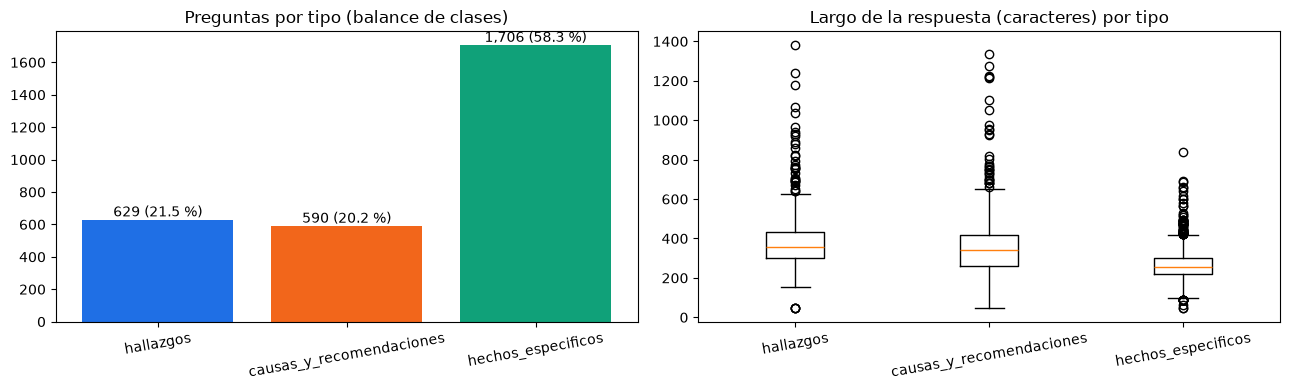

In [9]:
print(df[["largo_pregunta_palabras", "largo_contexto_palabras", "largo_respuesta_car"]].describe().round(1))

conteo = df["tipo_pregunta"].value_counts().reindex(CLASES).fillna(0).astype(int)
porc = (conteo / conteo.sum() * 100).round(1)
print("\n", pd.DataFrame({"preguntas": conteo, "%": porc}))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
barras = ejes[0].bar(conteo.index, conteo.values, color=[COLORES[c] for c in conteo.index])
ejes[0].bar_label(barras, labels=[f"{v:,} ({p} %)" for v, p in zip(conteo.values, porc.values)])
ejes[0].set_title("Preguntas por tipo (balance de clases)")
ejes[0].tick_params(axis="x", rotation=10)

ejes[1].boxplot([df.loc[df["tipo_pregunta"] == c, "largo_respuesta_car"] for c in CLASES], tick_labels=CLASES)
ejes[1].set_title("Largo de la respuesta (caracteres) por tipo")
ejes[1].tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.savefig(FIGURAS / "descripcion.png", dpi=110)
plt.show()

## Etapa 3 · Regresión lineal

**Pregunta:** ¿cuántos caracteres tendrá la respuesta de la IA, según cómo es la pregunta y cuánto contexto recibe?
Sirve para estimar costos y tiempos de un sistema de preguntas y respuestas: las IA cobran según la cantidad de texto que escriben.

**En palabras simples:** el modelo busca la mejor recta `y = w₁·x₁ + w₂·x₂ + … + b`.
Cada **w** (coeficiente) dice cuántos caracteres suma o resta esa variable, y **b** (intercepto) es el punto de partida.

| Variable (X) | Por qué la usamos |
|---|---|
| `largo_pregunta_palabras` | preguntas más largas suelen pedir más detalle |
| `largo_contexto_palabras` | con más texto de apoyo hay más que resumir |
| `tiene_contexto` | sin fragmento del informe la IA responde distinto |
| `tipo_hallazgos`, `tipo_hechos_especificos` | pedir hallazgos o recomendaciones genera respuestas más largas que un dato puntual |
| `generado_gpt4o` | cada IA tiene su propio estilo |

### 3.1 ¿Hay variables que dicen lo mismo? (colinealidad)
Si dos variables casi siempre valen lo mismo, la regresión no sabe a cuál darle el crédito y sus coeficientes se vuelven inestables.
Esta revisión usa solo las variables X, no el objetivo.

In [10]:
candidatas = ["largo_pregunta_palabras", "largo_contexto_palabras", "tiene_contexto",
              "tipo_hallazgos", "tipo_hechos_especificos", "generado_gpt4o"]
correlaciones = df[candidatas + ["menciona_codigo_informe"]].corr().round(2)
print(correlaciones, "\n")

corr_codigo = float(df["menciona_codigo_informe"].corr(df["tipo_hechos_especificos"]))
print(f"Correlación menciona_codigo_informe vs tipo_hechos_especificos: {corr_codigo:.2f}")
print("Decisión: se descarta menciona_codigo_informe porque repite la información de tipo_pregunta.")

# Una variable que vale siempre lo mismo no puede tener pendiente: se quita si aparece
X_REGRESION = [c for c in candidatas if df[c].nunique() > 1]
Y_REGRESION = "largo_respuesta_car"
print("Variables finales:", X_REGRESION)

                         largo_pregunta_palabras  largo_contexto_palabras  \
largo_pregunta_palabras                     1.00                     0.47   
largo_contexto_palabras                     0.47                     1.00   
tiene_contexto                              0.08                     0.14   
tipo_hallazgos                              0.32                     0.41   
tipo_hechos_especificos                    -0.63                    -0.44   
generado_gpt4o                             -0.26                    -0.25   
menciona_codigo_informe                     0.47                     0.37   

                         tiene_contexto  tipo_hallazgos  \
largo_pregunta_palabras            0.08            0.32   
largo_contexto_palabras            0.14            0.41   
tiene_contexto                     1.00            0.03   
tipo_hallazgos                     0.03            1.00   
tipo_hechos_especificos           -0.03           -0.62   
generado_gpt4o               

### 3.2 Entrenar con la clase `RegresionLineal`
`ejecutar` hace en orden: preparar → dividir 80/20 → entrenar (guarda el `.pkl` en `entrenamiento/`) → predecir → obtener w y b → evaluar.
Parámetros: `LinearRegression()` con sus **valores predeterminados**, `test_size=0.2` y `random_state=42`.

In [11]:
reg = RegresionLineal(feature_column=X_REGRESION, target_column=Y_REGRESION,
                      test_size=TEST_SIZE, random_state=SEMILLA)
r_reg = reg.ejecutar(df)
r_reg["metricas"]

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['largo_pregunta_palabras', 'largo_contexto_palabras', 'tiene_contexto', 'tipo_hallazgos', 'tipo_hechos_especificos', 'generado_gpt4o'], y='largo_respuesta_car'; 2925 filas válidas; 0 filas eliminadas; X=(2925, 6), y=(2925,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=2340 filas (2340, 6); prueba=585 filas (585, 6).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 2340 filas y 6 características.
[entrenar] modelo guardado en: entrenamiento/20261108_221911_937160_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento/20261108_221911_937160_modelo.pkl; 585 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento/20261108_221911_937

{'mae': 61.55512808527961, 'rmse': 96.493598725355, 'r2': 0.36301273772402454}

### 3.3 Comparar contra Pere, el modelo perezoso
Pere siempre predice el **promedio** del entrenamiento. Si nuestro modelo no le gana a Pere, no sirve.

In [12]:
pere_reg = DummyRegressor(strategy="mean").fit(reg.X_train, reg.y_train)
mae_pere = mean_absolute_error(reg.y_test, pere_reg.predict(reg.X_test))

pd.DataFrame({"MAE": [mae_pere, r_reg["metricas"]["mae"]],
              "R²": [0.0, r_reg["metricas"]["r2"]]},
             index=["Pere (promedio)", "Regresión lineal"]).round(3)

,MAE,R²
Pere (promedio),87.273,0.000
Regresión lineal,61.555,0.363


### 3.4 Leer los coeficientes
Las variables **no se escalaron**, así que cada w se lee en unidades reales: *caracteres por palabra* o *caracteres por tener la característica (1 vs 0)*.

In [13]:
print(f"Intercepto b = {reg.parametros['b']:.2f}")
Reportes.coeficientes_regresion(reg)

Intercepto b = 152.15


,variable,w,lectura
0,tiene_contexto,158.44,"si la pregunta trae contexto (1) frente a no traerlo (0), la respu..."
1,generado_gpt4o,-74.78,"si la respuesta la escribió gpt-4o (frente a otra IA), la respuest..."
2,tipo_hechos_especificos,-66.02,si la pregunta es de hechos específicos (frente a causas y recomen...
3,tipo_hallazgos,9.09,"si la pregunta pide hallazgos (frente a causas y recomendaciones),..."
4,largo_contexto_palabras,1.22,"por cada palabra más de contexto, la respuesta cambia +1.2 caracteres"
5,largo_pregunta_palabras,0.33,"por cada palabra más en la pregunta, la respuesta cambia +0.3 cara..."


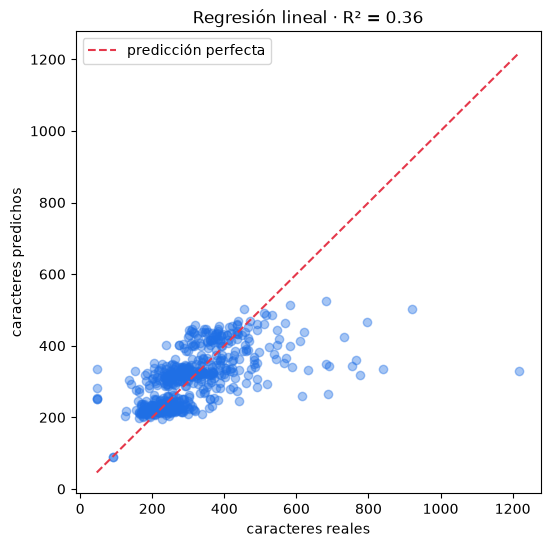

In [14]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(reg.y_test, r_reg["predicciones"], alpha=0.4, color="#1f6fe5")
limites = [min(reg.y_test.min(), r_reg["predicciones"].min()), max(reg.y_test.max(), r_reg["predicciones"].max())]
ax.plot(limites, limites, "--", color="#e5384b", label="predicción perfecta")
ax.set_xlabel("caracteres reales")
ax.set_ylabel("caracteres predichos")
ax.set_title(f"Regresión lineal · R² = {r_reg['metricas']['r2']:.2f}")
ax.legend()
plt.savefig(FIGURAS / "regresion_real_vs_predicho.png", dpi=110)
plt.show()

### 3.5 Lectura de resultados
- **MAE:** cuántos caracteres se equivoca el modelo en promedio. Más bajo es mejor.
- **RMSE:** parecido al MAE, pero castiga más los errores grandes.
- **R²:** qué parte de las diferencias de largo explica el modelo (1 = todo, 0 = igual que Pere).

In [15]:
for linea in Reportes.interpretar_regresion(reg, mae_pere):
    print("•", linea)

• MAE = 62: en promedio el modelo se equivoca en 62 caracteres, frente a respuestas que miden en promedio 308 (error típico del 20 %).
• RMSE = 96: es mayor que el MAE porque castiga más los errores grandes; algunas respuestas se salen mucho de lo esperado.
• R² = 0.36: el modelo explica cerca del 36 % de las diferencias de largo entre respuestas; el resto depende del contenido del informe, que el modelo no lee.
• Pere (predecir siempre el promedio) tiene MAE = 87; el modelo reduce el error en 29 %.
• R² entrenamiento = 0.35 vs prueba = 0.36: parecidos, no hay señales de sobreajuste (el modelo no memorizó).
• Variable con más peso: tiene_contexto (si la pregunta trae contexto (1) frente a no traerlo (0), la respuesta cambia +158.4 caracteres).
• b = 152: largo esperado cuando todas las variables valen 0 (pregunta de causas y recomendaciones, sin contexto, escrita por otra IA). Es el punto de partida de la recta; una pregunta de 0 palabras no existe en la realidad.


## Etapa 4 · Clasificación

**Pregunta:** leyendo **solo la respuesta**, ¿podemos saber qué tipo de pregunta se hizo?
Sirve para organizar miles de respuestas sobre el conflicto (por ejemplo, en un buscador de memoria histórica) aunque no se tenga la pregunta original.

- **Clases:** `hallazgos`, `causas_y_recomendaciones`, `hechos_especificos` (regla de la sección 2.3).
- **X:** el texto de `answer`, convertido en números con **TF-IDF**: una palabra pesa más si aparece mucho en *esa* respuesta y poco en las demás.
- **No se usa la pregunta** ni nada que salga de ella (como `menciona_codigo_informe`), porque de ella sale la etiqueta: sería darle al modelo la respuesta del examen.

**Algoritmo: regresión logística.** A pesar del nombre, es un clasificador: calcula la probabilidad de cada clase y elige la mayor.
Se eligió porque funciona muy bien con texto, es rápida y deja ver qué palabras usó para decidir.

| Parámetro | Valor | Por qué |
|---|---|---|
| `ngram_range` | (1, 2) | palabras sueltas y pares ("no repetición") |
| `max_features` | 3000 | vocabulario máximo |
| `min_df` | 2 | ignora palabras que aparecen en un solo texto |
| `stop_words` | lista en español | ignora "el", "de", "que"… |
| `class_weight` | "balanced" | da más peso a las clases con menos ejemplos |
| `max_iter` | 2000 | más intentos para que el modelo termine de ajustarse |
| `C` | 1.0 (predeterminado) | fuerza de la regularización |
| `test_size`, `random_state` | 0.2, 42 | división estratificada (misma proporción de clases) |

TF-IDF aprende el vocabulario **solo con entrenamiento** (está dentro de un `Pipeline`), así que no espía la prueba.

In [16]:
clf = ClasificadorTexto(
    modelo=LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEMILLA),
    columna_texto="answer", columna_objetivo="tipo_pregunta",
    test_size=TEST_SIZE, random_state=SEMILLA,
    ngram_range=(1, 2), max_features=3000, min_df=2, stop_words=STOPWORDS_ES,
    directorio_modelos="entrenamiento", eliminar_duplicados=True,
)
r_clf = clf.ejecutar(df)
r_clf["metricas"]["por_clase"].round(4)

[ejecutar][1/6] cargar_datos (LogisticRegression)
[ejecutar][2/6] preparar_datos
[preparar_datos] 2891 textos válidos; 34 filas eliminadas; clases: {'hechos_especificos': 1696, 'hallazgos': 625, 'causas_y_recomendaciones': 570}.
[ejecutar][3/6] dividir_datos
[dividir_datos] stratify=y; entrenamiento=2312; prueba=579; random_state=42.
[ejecutar][4/6] construir_modelo
[construir_modelo] TfidfVectorizer(1, 2) -> LogisticRegression
[ejecutar][5/6] entrenar
[entrenar] 2312 textos; modelo guardado en entrenamiento/20261108_221912_260975_LogisticRegression.pkl
[ejecutar][6/6] evaluar
[evaluar] exactitud=0.9136; F1 macro=0.9050; F1 ponderado=0.9142
                          precision    recall  f1-score   support

causas_y_recomendaciones     0.9153    0.9474    0.9310       114
               hallazgos     0.8271    0.8800    0.8527       125
      hechos_especificos     0.9482    0.9147    0.9311       340

                accuracy                         0.9136       579
               macr

,precision,recall,f1,casos
causas_y_recomendaciones,0.9153,0.9474,0.9310,114
hallazgos,0.8271,0.8800,0.8527,125
hechos_especificos,0.9482,0.9147,0.9311,340


### 4.1 Contra Pere: decir siempre la clase más común

In [17]:
pere_clf = DummyClassifier(strategy="most_frequent").fit(clf.X_train.to_frame(), clf.y_train)
clase_pere = pere_clf.classes_[np.argmax(pere_clf.class_prior_)]
exactitud_pere = accuracy_score(clf.y_test, pere_clf.predict(clf.X_test.to_frame()))

pd.DataFrame({"exactitud": [exactitud_pere, r_clf["metricas"]["exactitud"]],
              "F1 macro": [np.nan, r_clf["metricas"]["f1_macro"]]},
             index=[f"Pere (siempre {clase_pere})", "Regresión logística"]).round(4)

,exactitud,F1 macro
Pere (siempre hechos_especificos),0.5872,NaN
Regresión logística,0.9136,0.905


### 4.2 Matriz de confusión
Filas = clase real, columnas = clase predicha. La **diagonal** son los aciertos y lo demás son errores.

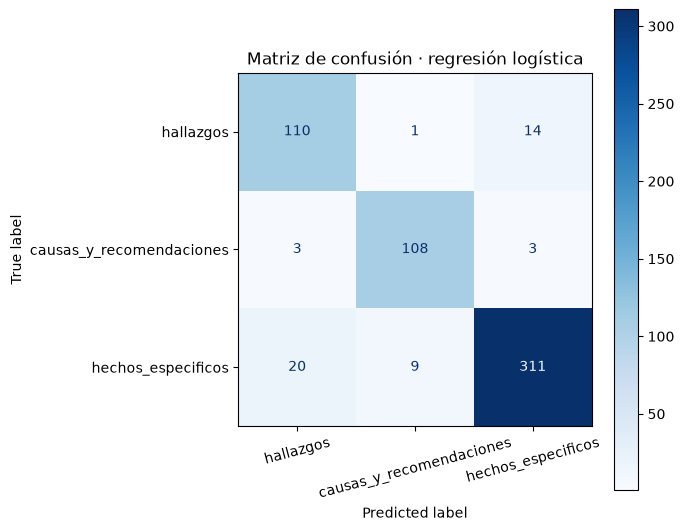

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(clf.y_test, r_clf["predicciones"], labels=CLASES,
                                        cmap="Blues", values_format=",d", ax=ax, xticks_rotation=15)
ax.set_title("Matriz de confusión · regresión logística")
plt.tight_layout()
plt.savefig(FIGURAS / "matriz_confusion.png", dpi=110)
plt.show()

### 4.3 Palabras que delatan cada clase

In [19]:
clf.palabras_clave(10)

,causas_y_recomendaciones,hallazgos,hechos_especificos
0,repeticion,destaca,testimonios
1,recomienda,resalta,documenta
2,causas,concluye,amenazas
3,estructurales,hallazgos,actos
4,causas estructurales,revela,casos
5,prevenir,hallazgos principales,reflejando
6,estructurales conflicto,principales,quienes
7,evitar,subraya,testimonios victimas
8,garantizar,necesidad,recoge
9,fortalecer,violaciones,describe


### 4.4 Ejemplos de errores

In [20]:
errores = pd.DataFrame({"respuesta": clf.X_test.to_numpy(), "real": clf.y_test.to_numpy(),
                        "predicho": r_clf["predicciones"]})
errores = errores[errores["real"] != errores["predicho"]]
print("Errores por tipo:\n", errores.groupby(["real", "predicho"]).size(), "\n")
errores.assign(respuesta=errores["respuesta"].str[:150]).head(5)

Errores por tipo:
 real                      predicho                
causas_y_recomendaciones  hallazgos                    3
                          hechos_especificos           3
hallazgos                 causas_y_recomendaciones     1
                          hechos_especificos          14
hechos_especificos        causas_y_recomendaciones     9
                          hallazgos                   20
dtype: int64 



,respuesta,real,predicho
12,Las recomendaciones incluyen reformas legales y estructurales para...,hechos_especificos,causas_y_recomendaciones
17,El informe establece que los pueblos indígenas han sido especialme...,causas_y_recomendaciones,hallazgos
18,"El informe subraya que el trabajo de memoria, a través de museos y...",causas_y_recomendaciones,hechos_especificos
40,El informe recomienda implementar políticas públicas intersecciona...,hechos_especificos,causas_y_recomendaciones
41,El informe evidencia que las comunidades indígenas fueron objeto d...,hechos_especificos,hallazgos


### 4.5 Lectura de resultados
- **Exactitud:** porcentaje de aciertos. Si las clases tienen tamaños distintos, puede engañar.
- **Precisión:** de las que el modelo dijo que eran de una clase, ¿cuántas lo eran?
- **Recall:** de las que realmente eran de una clase, ¿cuántas encontró?
- **F1:** equilibrio entre precisión y recall. El **F1 macro** promedia las clases dándoles el mismo peso, por eso es justo aunque estén desbalanceadas.

In [21]:
for linea in Reportes.interpretar_clasificacion(clf, exactitud_pere, clase_pere):
    print("•", linea)

• Exactitud = 91.4%: de cada 100 respuestas de prueba acierta el tipo de pregunta en unas 91.
• Pere (decir siempre 'hechos_especificos') acierta 58.7%; el modelo lo supera por 32.6 puntos.
• Las clases no tienen el mismo tamaño, así que también se usa F1 macro = 0.90 (promedio de F1 donde cada clase pesa igual) para que una clase pequeña no quede escondida.
• Clase que mejor reconoce: hechos_especificos (F1 = 0.93); la más difícil: hallazgos (F1 = 0.85).
• Error más frecuente: 20 respuestas de hechos_especificos se clasificaron como hallazgos; ocurre cuando una respuesta mezcla temas (hallazgos que también narran hechos concretos).


## Etapa 5 · Resumen automático
`Reportes.reporte_modelos` escribe el `.txt` con los resultados de **esta** ejecución: dataset, preprocesamiento, los dos modelos, métricas, interpretación, limitaciones, conclusiones y fecha.

In [22]:
ruta_reporte = Reportes().reporte_modelos(
    info_dataset={"dataset": DATASET, "config": CONFIG, "splits": SPLITS},
    df_crudo=df_crudo, df_preparado=df, calidad=calidad, registro=registro,
    regresion=reg, mae_perezoso=mae_pere,
    variable_descartada=("menciona_codigo_informe", corr_codigo),
    clasificador=clf, exactitud_perezoso=exactitud_pere, clase_perezoso=clase_pere,
    ruta="reportes/EA2_resumen_modelos.txt",
)
print(ruta_reporte.read_text(encoding="utf-8"))

[reporte_modelos] reporte guardado en: reportes/EA2_resumen_modelos.txt
RESUMEN AUTOMÁTICO · EA2 Modelos de predicción y clasificación
Fecha de ejecución: 2026-11-08 22:19:12 (hora de Colombia) · scikit-learn 1.9.1

1. DATASET
------------------------------------------------------------------------------
Identificador: jdavit/colombian-conflict-SQA
Enlace: https://huggingface.co/datasets/jdavit/colombian-conflict-SQA
Configuración: default · splits: ['train', 'test']
Contenido: preguntas y respuestas en español sobre informes del conflicto armado colombiano.
DataFrame crudo: 2925 filas x 5 columnas (question, context, answer, generated_by, split_origen)

2. PREPROCESAMIENTO
------------------------------------------------------------------------------
Validación (métrica y decisión):
                                           validación  métrica                              decisión
             Completitud · nulos (todas las columnas)        0           convertir a vacío y revisar
   

## Conclusiones

- **Regresión:** el largo de la respuesta depende sobre todo del **tipo de pregunta** y del **contexto**. El modelo da una estimación aproximada, no exacta: no lee el contenido del informe, solo mide los textos.
- **Clasificación:** la respuesta delata el tipo de pregunta porque la IA responde con patrones (por ejemplo, "recomendaciones" y "no repetición" en las preguntas de causas). Los errores aparecen cuando una respuesta mezcla temas.
- **Limitaciones generales:** las respuestas las escribió una IA, así que los modelos describen su estilo más que el conflicto. Además, varias preguntas tratan del mismo informe.
- **Siguiente paso:** dividir por informe (que un mismo informe no quede en entrenamiento y prueba) y probar modelos no lineales.

Los números exactos de esta ejecución están en `reportes/EA2_resumen_modelos.txt`.